In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [1]:
%pip install scikit-learn

In [4]:
from sklearn.datasets import fetch_california_housing
import pandas as pd

In [5]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

print("Rows and columns:", df.shape)
print("Columns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nFirst five rows:")
display(df.head())
print("\nSummary:")
display(df.describe().round(2))
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Rows and columns: (20640, 9)
Columns: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Data types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

First five rows:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00



Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate rows: 0


In [6]:
feature = "MedInc"
target = "MedHouseVal"

X = df[[feature]]
y = df[target]

print("Input feature:", feature)
print("Target:", target)
print("Target range:", round(y.min(), 3), "to", round(y.max(), 3))

Input feature: MedInc
Target: MedHouseVal
Target range: 0.15 to 5.0


In [8]:
import matplotlib.pyplot as plt

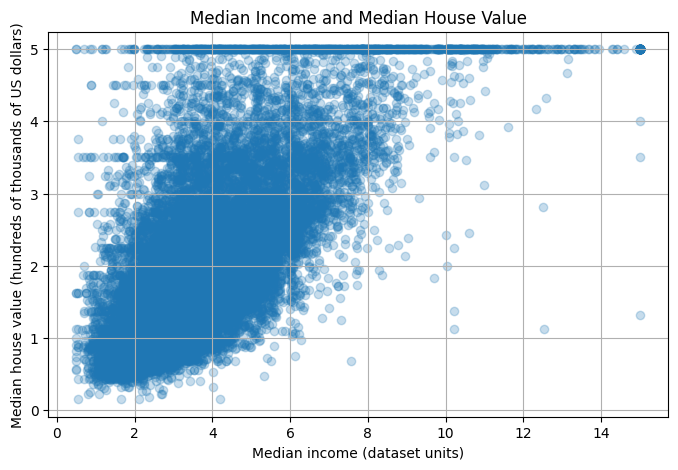

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(X[feature], y, alpha=0.25)
plt.title("Median Income and Median House Value")
plt.xlabel("Median income (dataset units)")
plt.ylabel("Median house value (hundreds of thousands of US dollars)")
plt.grid(True)
plt.show()

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 16512
Testing observations: 4128


In [14]:
from sklearn.linear_model import LinearRegression

In [15]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Coefficient for MedInc:", model.coef_[0])
print(
    f"Model equation: MedHouseVal = "
    f"{model.intercept_:.4f} + {model.coef_[0]:.4f} × MedInc"
)

Intercept: 0.4445972916907879
Coefficient for MedInc: 0.4193384939381271
Model equation: MedHouseVal = 0.4446 + 0.4193 × MedInc


In [16]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual MedHouseVal": y_test,
    "Predicted MedHouseVal": y_pred
})

display(comparison.head(10).round(3))

,Actual MedHouseVal,Predicted MedHouseVal
20046,0.477,1.150
3024,0.458,1.506
15663,5.000,1.904
20484,2.186,2.851
9814,2.780,2.007
13311,1.587,2.422
7113,1.982,2.576
7668,1.575,1.992
18246,3.400,2.459
5723,4.466,3.847


In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [19]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

MAE:  0.6299
MSE:  0.7091
RMSE: 0.8421
R²:   0.4589


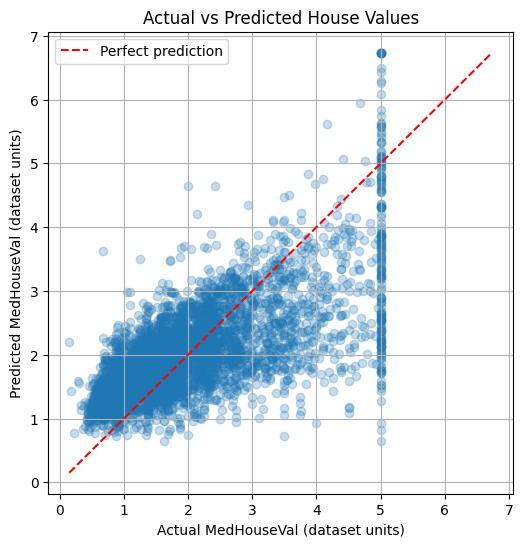

In [20]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.25)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")

plt.title("Actual vs Predicted House Values")
plt.xlabel("Actual MedHouseVal (dataset units)")
plt.ylabel("Predicted MedHouseVal (dataset units)")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
new_income = 5.0  # example MedInc value; keep it within the observed range
new_prediction = model.predict(pd.DataFrame({"MedInc": [new_income]}))[0]

print(f"MedInc input: {new_income}")
print(f"Predicted MedHouseVal: {new_prediction:.3f}")
print(f"Approximate value in US dollars: ${new_prediction * 100_000:,.0f}")

MedInc input: 5.0
Predicted MedHouseVal: 2.541
Approximate value in US dollars: $254,129
